# Assignment 5 — Random-Walk Agent in a 2D Grid

**Objective:** Program a random-walk agent that moves randomly in a grid until it reaches a target.

The agent does not calculate the shortest path. At every step, it randomly chooses one valid direction and keeps moving until it reaches the target.

## Basic idea

The agent follows a simple cycle:

**Observe current position → Find valid moves → Pick one randomly → Move → Check target → Repeat**

This is useful for demonstrating how an agent behaves when its movement decisions are random rather than based on a planned path.

In [1]:
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

## Step 1 — Create the grid

We use an 8 × 8 grid. The agent starts at the top-left corner and the target is at the bottom-right corner.

In [2]:
rows = 6
cols = 6

start = (0, 0)
target = (5, 5)

print("Grid size:", rows, "x", cols)
print("Start position:", start)
print("Target position:", target)

Grid size: 6 x 6
Start position: (0, 0)
Target position: (5, 5)


## Step 2 — Find valid movements

The agent can move **up, down, left, or right**. It cannot move outside the grid.

In [3]:
directions = {
    "Up": (-1, 0),
    "Down": (1, 0),
    "Left": (0, -1),
    "Right": (0, 1)
}

def get_valid_moves(position):
    row, col = position
    valid_moves = []

    for move, (dr, dc) in directions.items():
        new_row = row + dr
        new_col = col + dc

        if 0 <= new_row < rows and 0 <= new_col < cols:
            valid_moves.append((move, (new_row, new_col)))

    return valid_moves

## Step 3 — Run the random-walk agent

At every step, the agent chooses one of the valid movements randomly. The same cell can be visited multiple times, which is an important part of a random walk.

In [4]:
agent = start
path = [agent]
moves_taken = []

while agent != target:
    valid_moves = get_valid_moves(agent)

    # Randomly choose one valid move
    move_name, new_position = random.choice(valid_moves)

    agent = new_position
    path.append(agent)
    moves_taken.append(move_name)

print("Target reached!")
print("Total steps:", len(path) - 1)
print("Final position:", agent)

Target reached!
Total steps: 38
Final position: (5, 5)


## Step 4 — Show the path

The next cell displays the complete path taken by the agent. The repeated cells, if any, show that the agent sometimes moves back to a position it has already visited.

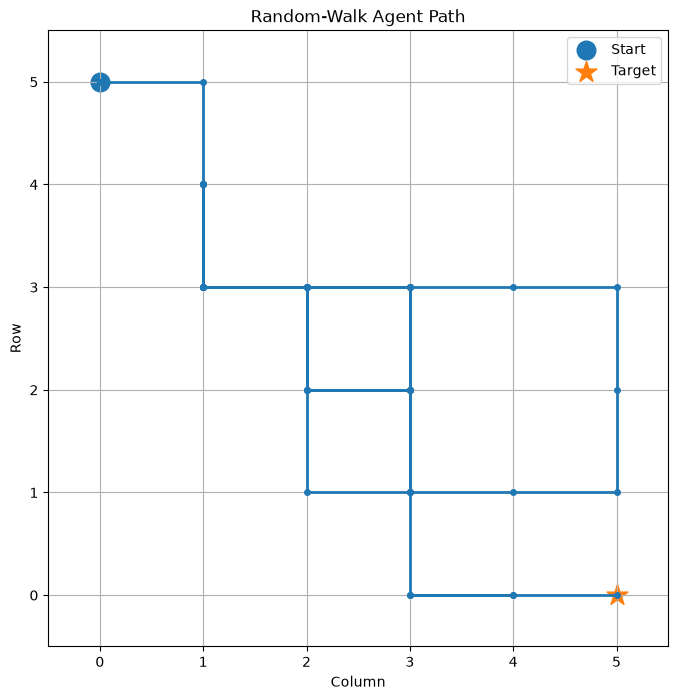

In [5]:
plt.figure(figsize=(8, 8))

x = [position[1] for position in path]
y = [rows - 1 - position[0] for position in path]

plt.plot(x, y, marker='o', linewidth=2, markersize=4)

plt.scatter(start[1], rows - 1 - start[0], s=180, marker='o', label='Start')
plt.scatter(target[1], rows - 1 - target[0], s=250, marker='*', label='Target')

plt.xticks(range(cols))
plt.yticks(range(rows))
plt.xlim(-0.5, cols - 0.5)
plt.ylim(-0.5, rows - 0.5)
plt.grid(True)
plt.xlabel("Column")
plt.ylabel("Row")
plt.title("Random-Walk Agent Path")
plt.legend()
plt.show()

## Step 5 — Animated simulation

This animation is useful for the presentation because it shows the agent moving one step at a time. Every movement is chosen randomly from the valid directions.

In [6]:
# Run a fresh simulation for the animation
agent = start
animation_path = [agent]
step = 0

while agent != target:
    valid_moves = get_valid_moves(agent)
    _, agent = random.choice(valid_moves)
    animation_path.append(agent)
    step += 1

    clear_output(wait=True)

    plt.figure(figsize=(7, 7))

    x = [position[1] for position in animation_path]
    y = [rows - 1 - position[0] for position in animation_path]

    plt.plot(x, y, marker='o', linewidth=2, markersize=4)
    plt.scatter(agent[1], rows - 1 - agent[0], s=220, marker='o', label='Agent')
    plt.scatter(start[1], rows - 1 - start[0], s=150, marker='s', label='Start')
    plt.scatter(target[1], rows - 1 - target[0], s=250, marker='*', label='Target')

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.xlim(-0.5, cols - 0.5)
    plt.ylim(-0.5, rows - 0.5)
    plt.grid(True)
    plt.title(f"Random Walk — Step {step}")
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.legend()
    plt.show()

    time.sleep(0.15)

clear_output(wait=True)
print("Agent reached the target!")
print("Total steps taken:", step)

Agent reached the target!
Total steps taken: 86


## Step 6 — Final result

Run the following cell after the animation to see a clean summary of the simulation.

In [7]:
print("Random-Walk Agent")
print("------------------")
print("Starting position:", start)
print("Target position:", target)
print("Steps taken:", len(animation_path) - 1)
print("Target reached: Yes")

Random-Walk Agent
------------------
Starting position: (0, 0)
Target position: (5, 5)
Steps taken: 86
Target reached: Yes


## What to explain in the lecture

**What is a random-walk agent?**  
It is an agent whose next movement is selected randomly from the valid actions available at its current position.

**Does it find the shortest path?**  
No. The agent has no path-planning algorithm, so it may move away from the target or revisit the same cells.

**When does it stop?**  
It stops when its current position becomes equal to the target position.

**Why can the number of steps change every time?**  
Because the movement is random. Running the same program again can produce a completely different path and number of steps.

## Simple flow of the agent

```text
       Start
         ↓
  Check current position
         ↓
    Find valid moves
         ↓
   Pick a move randomly
         ↓
       Move
         ↓
   Is target reached?
      /        \
    No          Yes
    ↓            ↓
  Repeat       Stop
```

### Note

The animation is intentionally simple. The goal of this assignment is to demonstrate the **random-walk behavior**, not to make the agent intelligent or optimal.